<a href="https://colab.research.google.com/github/diogenesjusto/FIAP/blob/master/Gradua%C3%A7%C3%A3o/2026/2TSCPV_20261020.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [34]:
import pandas as pd
from sklearn.linear_model import LinearRegression


In [2]:
df = pd.read_csv('https://raw.githubusercontent.com/diogenesjusto/FIAP/refs/heads/master/dados/credit_features_formatado.csv')

/tmp/ipykernel_5422/2505780036.py:1: DtypeWarning: Columns (52,53) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('https://raw.githubusercontent.com/diogenesjusto/FIAP/refs/heads/master/dados/credit_features_formatado.csv')


In [3]:
df

,Unnamed: 0,ID_CLIENTE,TIPO_FUNCIONARIO,DIA_PAGAMENTO,TIPO_ENVIO_APLICACAO,QUANT_CARTOES_ADICIONAIS,TIPO_ENDERECO_POSTAL,SEXO,ESTADO_CIVIL,QUANT_DEPENDENTES,...,FLAG_DOCUMENTO_RESIDENCIAL,FLAG_RG,FLAG_CPF,FLAG_COMPROVANTE_RENDA,PRODUTO,FLAG_REGISTRO_ACSP,IDADE,CEP_RESIDENCIAL_3,CEP_PROFISSIONAL_3,ROTULO_ALVO_MAU=1
0,0,1,C,5,Web,0,1,F,6,1,...,0,0,0,0,1,N,32,595,595,1
1,1,2,C,15,Carga,0,1,F,2,0,...,0,0,0,0,1,N,34,230,230,1
2,2,3,C,5,Web,0,1,F,2,0,...,0,0,0,0,1,N,27,591,591,0
3,3,4,C,20,Web,0,1,F,2,0,...,0,0,0,0,1,N,61,545,545,0
4,4,5,C,10,Web,0,1,M,2,0,...,0,0,0,0,1,N,48,235,235,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,49995,49996,C,10,0,0,1,F,1,2,...,0,0,0,0,1,N,36,591,591,1
49996,49996,49997,C,25,0,0,1,F,1,0,...,0,0,0,0,2,N,21,186,186,0
49997,49997,49998,C,5,Web,0,1,M,2,3,...,0,0,0,0,1,N,41,715,715,0
49998,49998,49999,C,1,Web,0,1,F,1,1,...,0,0,0,0,1,N,28,320,320,1


## Discretização por largura fixa

<Axes: >

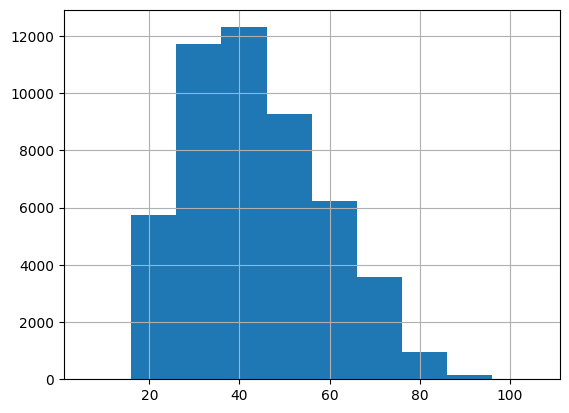

In [4]:
df['IDADE'].hist()

In [6]:
!pip install feature-engine

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 243.5/243.5 kB 3.0 MB/s eta 0:00:00


In [7]:
from feature_engine.discretisation import EqualWidthDiscretiser

In [16]:
# Queremos montar uma discretização de largura fixa
discEW = EqualWidthDiscretiser(bins=5, variables=['IDADE'])
discEW.fit(df)
dfCredT = discEW.transform(df)
dfCredT.groupby('IDADE').count()

,Unnamed: 0,ID_CLIENTE,TIPO_FUNCIONARIO,DIA_PAGAMENTO,TIPO_ENVIO_APLICACAO,QUANT_CARTOES_ADICIONAIS,TIPO_ENDERECO_POSTAL,SEXO,ESTADO_CIVIL,QUANT_DEPENDENTES,...,NIVEL_EDUCACIONAL_CONJUGE,FLAG_DOCUMENTO_RESIDENCIAL,FLAG_RG,FLAG_CPF,FLAG_COMPROVANTE_RENDA,PRODUTO,FLAG_REGISTRO_ACSP,CEP_RESIDENCIAL_3,CEP_PROFISSIONAL_3,ROTULO_ALVO_MAU=1
IDADE,,,,,,,,,,,,,,,,,,,,,
0,6763,6763,6763,6763,6763,6763,6763,6763,6763,6763,...,2182,6763,6763,6763,6763,6763,6763,6763,6763,6763
1,24106,24106,24106,24106,24106,24106,24106,24106,24106,24106,...,8596,24106,24106,24106,24106,24106,24106,24106,24106,24106
2,15029,15029,15029,15029,15029,15029,15029,15029,15029,15029,...,5358,15029,15029,15029,15029,15029,15029,15029,15029,15029
3,3977,3977,3977,3977,3977,3977,3977,3977,3977,3977,...,1479,3977,3977,3977,3977,3977,3977,3977,3977,3977
4,125,125,125,125,125,125,125,125,125,125,...,47,125,125,125,125,125,125,125,125,125


## Discretização por frequência - ou seja, escolhemos o % de elementos dentro de cada intervalo

In [22]:
from sklearn.preprocessing import KBinsDiscretizer
discKB = KBinsDiscretizer(n_bins=5, encode='ordinal', strategy='quantile')
dfCredT2 = discKB.fit_transform(df[['IDADE']])
df['DiscKB'] = dfCredT2

df.groupby('DiscKB').count()

,Unnamed: 0,ID_CLIENTE,TIPO_FUNCIONARIO,DIA_PAGAMENTO,TIPO_ENVIO_APLICACAO,QUANT_CARTOES_ADICIONAIS,TIPO_ENDERECO_POSTAL,SEXO,ESTADO_CIVIL,QUANT_DEPENDENTES,...,FLAG_DOCUMENTO_RESIDENCIAL,FLAG_RG,FLAG_CPF,FLAG_COMPROVANTE_RENDA,PRODUTO,FLAG_REGISTRO_ACSP,IDADE,CEP_RESIDENCIAL_3,CEP_PROFISSIONAL_3,ROTULO_ALVO_MAU=1
DiscKB,,,,,,,,,,,,,,,,,,,,,
0.0,9055,9055,9055,9055,9055,9055,9055,9055,9055,9055,...,9055,9055,9055,9055,9055,9055,9055,9055,9055,9055
1.0,9706,9706,9706,9706,9706,9706,9706,9706,9706,9706,...,9706,9706,9706,9706,9706,9706,9706,9706,9706,9706
2.0,11019,11019,11019,11019,11019,11019,11019,11019,11019,11019,...,11019,11019,11019,11019,11019,11019,11019,11019,11019,11019
3.0,10095,10095,10095,10095,10095,10095,10095,10095,10095,10095,...,10095,10095,10095,10095,10095,10095,10095,10095,10095,10095
4.0,10125,10125,10125,10125,10125,10125,10125,10125,10125,10125,...,10125,10125,10125,10125,10125,10125,10125,10125,10125,10125


## Feature Importance

# 1.1 Avaliação de coeficientes

In [24]:
dfPIB = pd.read_csv('https://raw.githubusercontent.com/diogenesjusto/FIAP/refs/heads/master/Gradua%C3%A7%C3%A3o/dados/pib.csv')

In [25]:
dfPIB

,Unnamed: 0,ANO_MES,PIB,BRL,BRP,BRT,SLP,SPP,SPT,PRL,...,PIBi3,PIBi4,PIBi5,PIBi6,PIBi7,PIBi8,PIBi9,PIBi10,PIBi11,PIBi12
0,1,jan/04,103.09,109.19,108.67,109.08,102.84,114.27,105.38,127.49,...,106.27,104.52,102.59,102.24,99.96,101.93,101.17,101.70,100.03,100.00
1,2,fev/04,102.05,95.65,104.52,97.63,90.76,109.83,94.99,96.60,...,104.10,106.27,104.52,102.59,102.24,99.96,101.93,101.17,101.70,100.03
2,3,mar/04,110.43,91.69,125.53,99.26,89.78,133.24,99.43,83.79,...,103.91,104.10,106.27,104.52,102.59,102.24,99.96,101.93,101.17,101.70
3,4,abr/04,106.77,95.36,118.34,100.49,94.58,123.55,101.02,91.79,...,103.09,103.91,104.10,106.27,104.52,102.59,102.24,99.96,101.93,101.17
4,5,mai/04,108.08,92.47,121.49,98.96,91.34,128.32,99.55,85.73,...,102.05,103.09,103.91,104.10,106.27,104.52,102.59,102.24,99.96,101.93
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
133,134,fev/15,144.42,147.35,133.73,143.57,147.81,148.96,147.54,157.30,...,151.46,156.65,154.04,154.75,154.34,148.92,154.49,150.92,151.44,148.92
134,135,mar/15,151.68,149.64,163.27,152.09,154.87,179.07,159.56,147.28,...,150.70,151.46,156.65,154.04,154.75,154.34,148.92,154.49,150.92,151.44
135,136,abr/15,147.03,153.81,149.93,152.28,161.21,164.74,161.16,162.21,...,149.51,150.70,151.46,156.65,154.04,154.75,154.34,148.92,154.49,150.92
136,137,mai/15,148.94,149.66,153.03,149.82,157.03,169.39,158.76,149.06,...,144.42,149.51,150.70,151.46,156.65,154.04,154.75,154.34,148.92,154.49


In [39]:
treino = dfPIB.iloc[0:126]
teste = dfPIB.iloc[126:]

X = ['SLP', 'SPP', 'RJL', 'RJP']
X_treino = treino.loc[: ,X]
Y_treino = treino.loc[: ,['PIB']]

mod = LinearRegression()
mod.fit(X_treino, Y_treino)

# Análise dos coeficientes
mod.coef_

array([[ 0.47091547,  0.43530889, -0.31786917,  0.00223493]])

# 1.2 Split (RandomForest)

In [40]:
from sklearn.ensemble import RandomForestRegressor

modRF = RandomForestRegressor()
modRF.fit(X_treino, Y_treino)

# Análise dos coeficientes
modRF.feature_importances_

/usr/local/lib/python3.13/dist-packages/sklearn/base.py:1389: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


array([0.05590202, 0.54828801, 0.01623458, 0.37957539])

<Axes: >

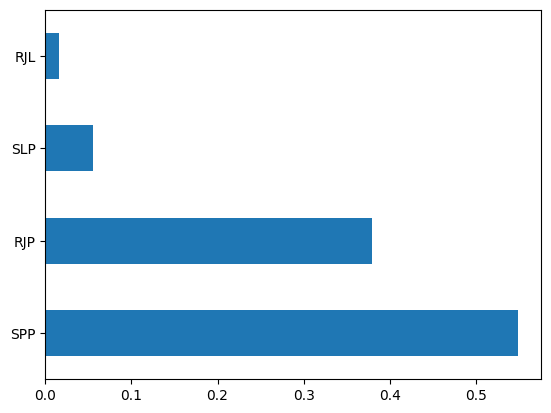

In [41]:
# Visualização gráfica de importância de variáveis
feature_importance = pd.Series(modRF.feature_importances_, index=modRF.feature_names_in_)
feature_importance.nlargest(6).plot(kind='barh')

# 1.3 Permutação (técnica que se utiliza tanto treinamento quanto teste)


<BarContainer object of 4 artists>

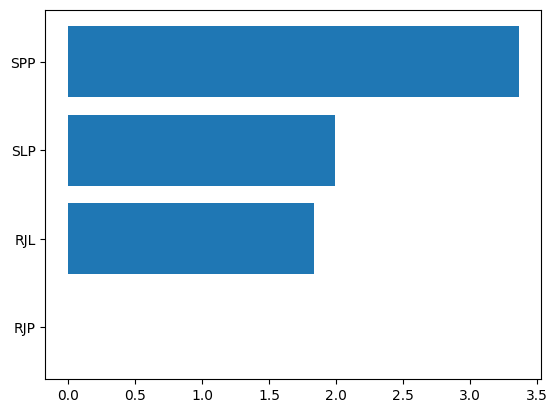

In [67]:
from sklearn.inspection import permutation_importance
import matplotlib as plt

X_teste = teste.loc[:,X]
Y_teste = teste.iloc[:,2]

# Como o método é agnóstico a modelo, devemos escolher a qual o modelo aplicaremos a análise
# Por exemplo, acima construímos mod (regressão linear) e modRF (randomForest).
# A permutação pode ser utilizada com quaisquer um dos modelos

perm_importance = permutation_importance(mod, X_teste, Y_teste, random_state=1, n_repeats=200 )
#perm_importance = permutation_importance(modRF, X_teste, Y_teste)
perm_importance

# Visualizacao gráfica
ordem_idx = perm_importance.importances_mean.argsort()
plt.pyplot.barh(X_teste.columns[ordem_idx], perm_importance.importances_mean[ordem_idx])